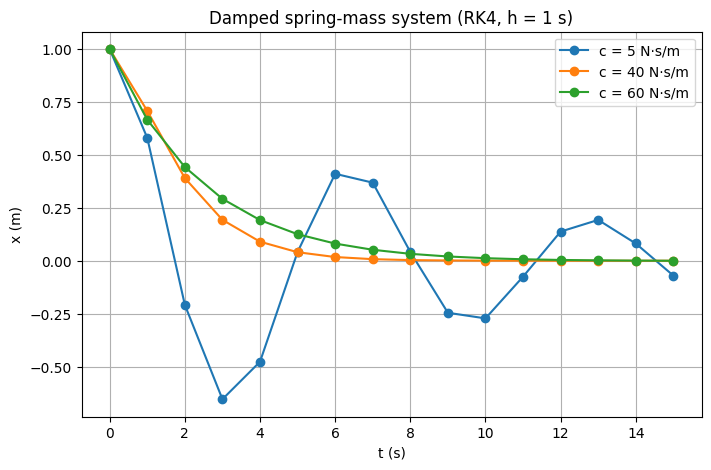

In [2]:
import numpy as np
import matplotlib.pyplot as plt

m, k = 20.0, 20.0

def f(t, u, c):
    """u = [x, v]; returns [dx/dt, dv/dt]"""
    x, v = u
    return np.array([v, -(c * v + k * x) / m])

def rk4(c, u0, t0, tf, h):
    n = int(round((tf - t0) / h))
    t = np.linspace(t0, tf, n + 1)
    u = np.zeros((n + 1, 2))
    u[0] = u0
    for i in range(n):
        k1 = f(t[i],         u[i],                c)
        k2 = f(t[i] + h/2,   u[i] + h/2 * k1,     c)
        k3 = f(t[i] + h/2,   u[i] + h/2 * k2,     c)
        k4 = f(t[i] + h,     u[i] + h * k3,       c)
        u[i + 1] = u[i] + h/6 * (k1 + 2*k2 + 2*k3 + k4)
    return t, u

u0 = [1.0, 0.0]         
h = 1.0                 
plt.figure(figsize=(8, 5))
for c in [5, 40, 60]:
    t, u = rk4(c, u0, 0.0, 15.0, h)
 #print(f"c = {c} N·s/m")
    #for ti, xi in zip(t, u[:, 0]):
        #print(f"  t = {ti:4.1f}  x = {xi: .6f}")
    plt.plot(t, u[:, 0], 'o-', label=f"c = {c} N·s/m")

plt.xlabel("t (s)")
plt.ylabel("x (m)")
plt.title("Damped spring-mass system (RK4, h = 1 s)")
plt.grid(True)
plt.legend()
plt.show()